# Polygonal trajectories, single-section arm (SI Section 6.10, Figs. S7 to S9)

A triangle, a square and a hexagon inscribed in the two circles of Fig. 6 of the main text (radius $35$ mm at $z = 115$ mm, orange; radius $25$ mm at $z = 125$ mm, blue)
are tracked by the four controllers. Each panel shows the top view (X-Y) and the side view (X-Z) of the motion-capture tip trajectory against the commanded polygon (dashed), with the conventions of Fig. 6.

**Inputs** (repository): `results/PolygonWS_<sides>_<height>_<controller>.npz` (array `mocap`: tip position [mm]), recorded by `SINGLE_control_test.py`.
**Outputs**: `results/figS7_triangle.pdf`, `results/figS8_square.pdf`, `results/figS9_hexagon.pdf`. Run from inside `SINGLE/`.

In [1]:
import shutil
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "gray", "grid.linewidth": 0.5, "grid.alpha": 0.3,
    "text.usetex": shutil.which("latex") is not None, "mathtext.fontset": "cm",
})

SHAPES = {3: "figS7_triangle", 4: "figS8_square", 6: "figS9_hexagon"}
CIRCLES = {"115": {"radius": 35, "color": "#ff7f0e"},   # lower polygon, orange
           "125": {"radius": 25, "color": "#1f77b4"}}   # upper polygon, blue
CONTROLLERS = [("a", "jacobian_mocap", "Model-based, closed-loop"),
               ("b", "datadriven_mocap", "Data-driven, closed-loop"),
               ("c", "OL_jacobian", "Model-based, open-loop"),
               ("d", "OL_datadriven", "Data-driven, open-loop")]
REF_COLOR = "#2c3e50"


def polygon_vertices(n_sides, radius, height):
    """Regular polygon on the plane z = height, first vertex on the +X axis, closed."""
    ang = np.linspace(0, 2 * np.pi, n_sides, endpoint=False)
    v = np.stack((radius * np.cos(ang), radius * np.sin(ang), np.full(n_sides, float(height))), axis=1)
    return np.vstack((v, v[:1]))

## Figs. S7 (triangle), S8 (square) and S9 (hexagon)

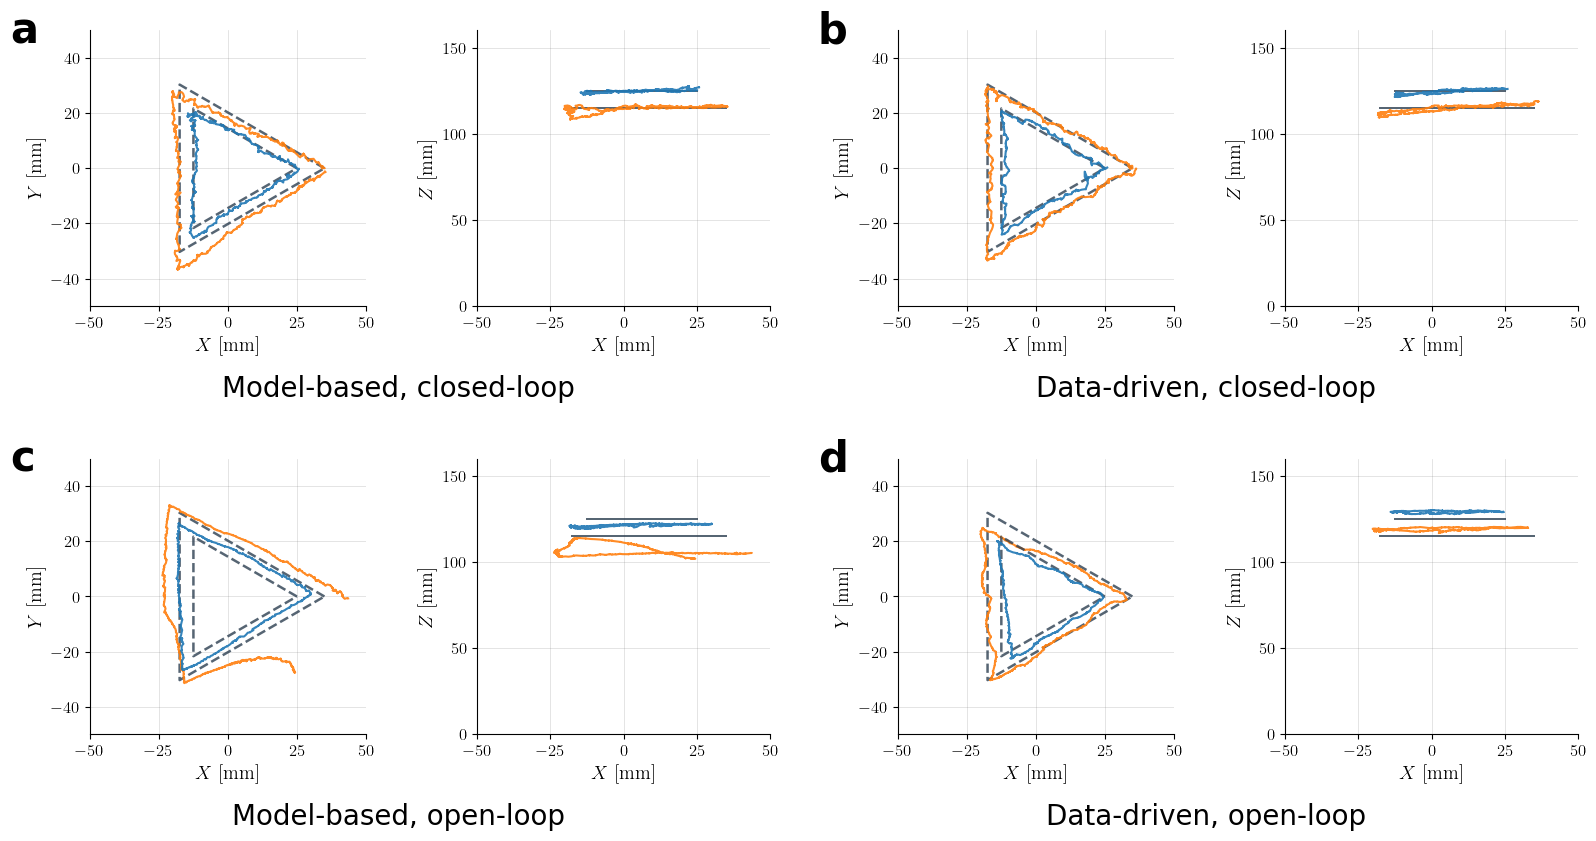

Saved results/figS7_triangle.pdf


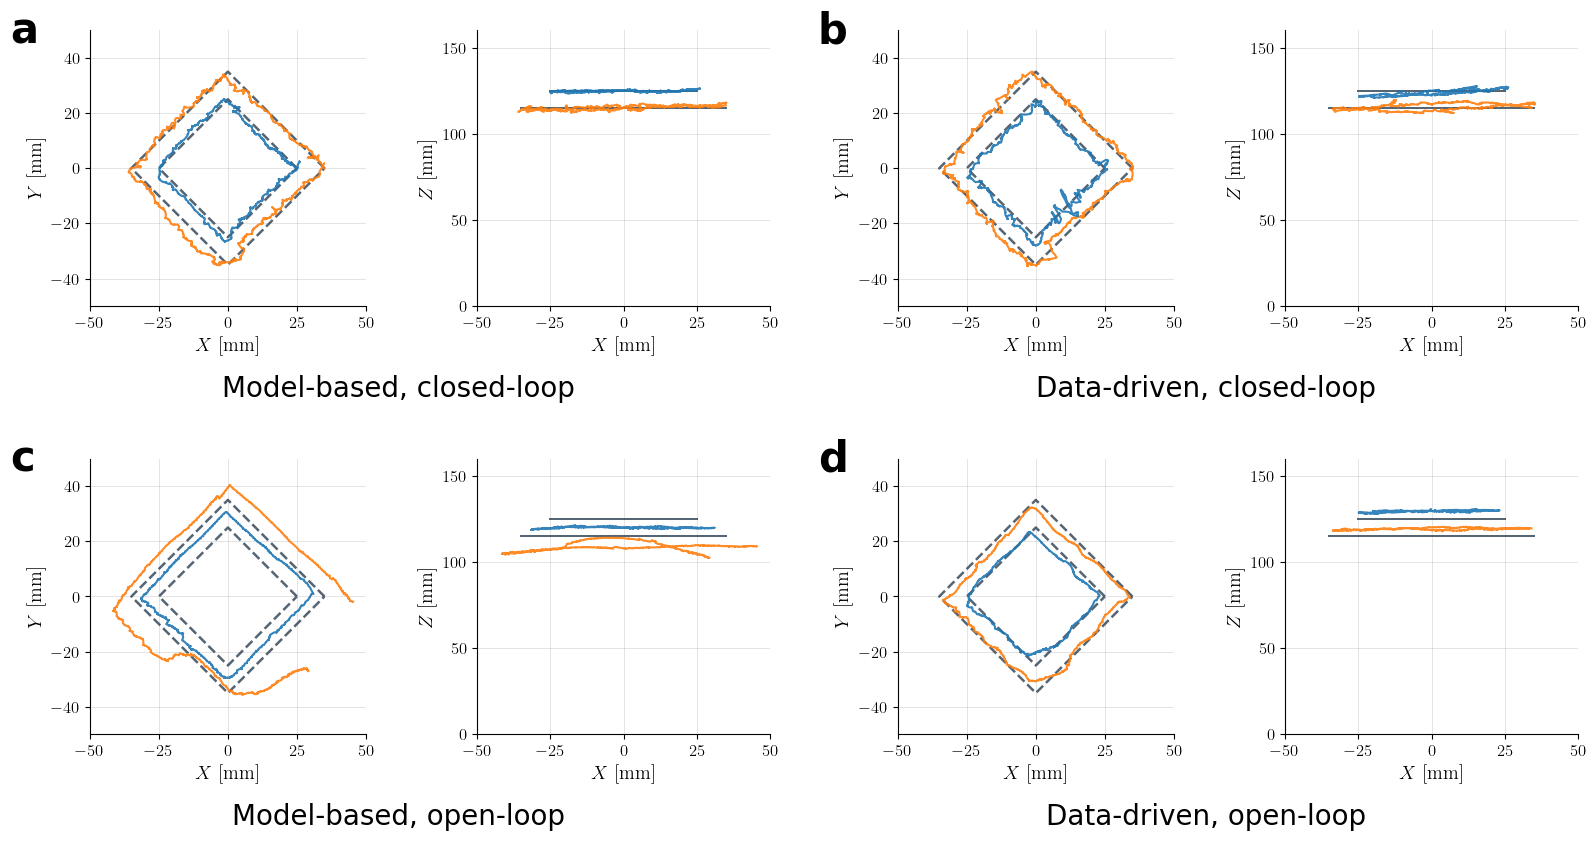

Saved results/figS8_square.pdf


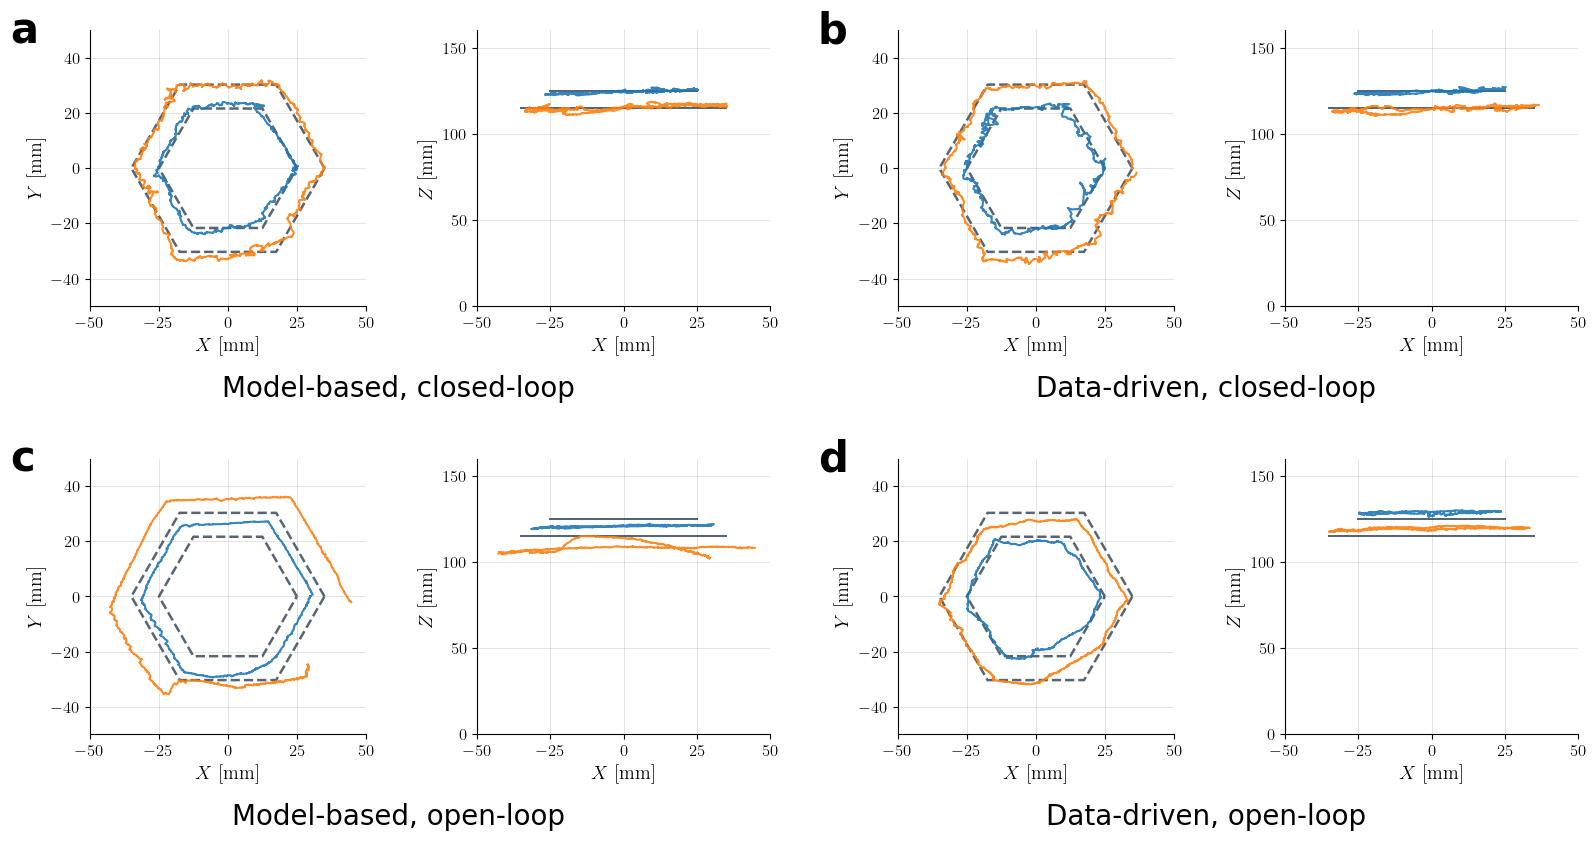

Saved results/figS9_hexagon.pdf


In [2]:
for n_sides, out_name in SHAPES.items():
    fig = plt.figure(figsize=(16, 8.4))
    subfigs = fig.subfigures(2, 2, hspace=0.04, wspace=0.02)
    for sf, (letter, key, title) in zip(subfigs.flat, CONTROLLERS):
        ax_xy, ax_xz = sf.subplots(1, 2, gridspec_kw={"wspace": 0.35})
        for height, st in CIRCLES.items():
            ref = polygon_vertices(n_sides, st["radius"], height)
            mocap = np.load(f"results/PolygonWS_{n_sides}_{height}_{key}.npz")["mocap"]
            ax_xy.plot(ref[:, 0], ref[:, 1], "--", color=REF_COLOR, lw=1.8, alpha=0.8)
            ax_xy.plot(mocap[:, 0], mocap[:, 1], "-", color=st["color"], lw=1.5, alpha=0.9)
            ax_xz.plot(ref[:, 0], ref[:, 2], "-", color=REF_COLOR, lw=1.2, alpha=0.8)
            ax_xz.plot(mocap[:, 0], mocap[:, 2], "-", color=st["color"], lw=1.5, alpha=0.9)
        ax_xy.set(xlim=(-50, 50), ylim=(-50, 50), xticks=np.arange(-50, 51, 25), yticks=np.arange(-40, 41, 20),
                  xlabel=r"$X$ [mm]", ylabel=r"$Y$ [mm]")
        ax_xy.set_aspect("equal")
        ax_xz.set(xlim=(-50, 50), ylim=(0, 160), xticks=np.arange(-50, 51, 25), yticks=np.arange(0, 151, 50),
                  xlabel=r"$X$ [mm]", ylabel=r"$Z$ [mm]")
        sf.subplots_adjust(left=0.1, right=0.97, top=0.92, bottom=0.25)
        sf.text(0.01, 0.97, letter, fontsize=30, fontweight="bold", family="sans-serif", usetex=False, va="top")
        sf.text(0.5, 0.03, title, fontsize=20, family="sans-serif", usetex=False, ha="center")
    fig.savefig(f"results/{out_name}.pdf", bbox_inches="tight")
    plt.show()
    print(f"Saved results/{out_name}.pdf")